# A história da política industrial nos PPAs de Santa Catarina, 2004-2027

Seis planos plurianuais, vinte anos, todos os programas do plano (529 códigos distintos nos Anexos Únicos), dos quais 42 pares programa-PPA são de política industrial. Este notebook conta, em capítulos, o que a política industrial diz, o que faz, para quem e com quanto dinheiro, sempre comparando com o plano inteiro. Recupera a narrativa da primeira versão (palavras de cada PPA, evolução dos termos, similaridade entre planos). Os testes completos estão em `analise_ppa_inteiro.ipynb` e `redes_ppa.ipynb`.

**A história em seis frases**

1. **Na política industrial, competitividade sobe e inovação cai.** A alta de competitividade em 2024-2027 é o único movimento que passa no teste (p = 0,004). Que uma toma o lugar da outra é uma leitura sustentada pelo deslocamento dos programas e das palavras (capítulos 3 e 4), não por um teste.
2. **A inovação sai da política industrial** e passa a ser palavra de modernização do Estado.
3. **A política industrial fala parecido, mas a partir de 2020 faz coisas diferentes.**
4. **Quem recebe:** o público "empresas" perde espaço; em 2024-2027, municípios recebem um pouco mais que empresas na política industrial.
5. **A política industrial perde peso no orçamento e também encolhe em reais:** de 3,1% para 1,2% do PPA, e de R$ 1,4 bilhão por ano (2007) para R$ 0,78 bilhão (2024-2027), a preços de 2024.
6. **O plano de 2024-2027 copia 74% do anterior, mas a política industrial é reescrita.** A alternância de governo, sozinha, não explica isso.

Como contraste, no plano inteiro o único tema que muda é o agro, que sai de cena.

**Medida e testes.** Contagem e % dos lemas (substantivos, verbos e adjetivos de objetivo + justificativa). Teste principal: **variação** do tema entre os PPAs, por permutação do PPA de cada programa (3.000 sorteios). Com 6 temas testados (as 5 dimensões do léxico e o agro), o limite corrigido (Bonferroni) é 0,05 / 6 ≈ **0,008**. A tendência no tempo é teste complementar. Afirmação que não sai dos documentos: [verificar].

In [1]:
# No Google Colab: baixa o repositório com os resultados. No computador local, não faz nada.
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/tcc"):
        !git clone -q https://github.com/andreydeps/tcc-politica-industrial-sc.git /content/tcc
    %cd /content/tcc

In [2]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
S = RAIZ / "saidas"
sys.path.insert(0, str(RAIZ / "scripts"))
from ppa_inteiro_analise import carregar, PER, item7_ngramas
from historia import (palavras_caracteristicas, temas_no_tempo, agro, quem_fala_de_inovacao, dizem_fazem,
                      quem_recebe, orcamento, copia)

p, s, f = carregar()

def fig(nome, largura=950):
    display(Image(filename=str(S / nome), width=largura))

def tabela(df, casas=1, p_cols=("p variação", "p tendência", "texto: p", "subações: p")):
    num = lambda k: (lambda v: "" if pd.isna(v) else f"{v:,.{k}f}".replace(",", "X").replace(".", ",").replace("X", "."))
    fmt = {c: num(0 if pd.api.types.is_integer_dtype(df[c]) else 3 if c in p_cols else casas)
           for c in df.select_dtypes("number").columns}
    display(df.style.hide(axis="index").format(fmt))

## 0. Os planos

In [3]:
tabela(p.groupby("periodo").agg(**{"programas no PPA (todos entram na análise)": ("codigo", "size"),
                                   "dos quais de política industrial": ("selecionado", "sum"),
                                   "lemas (todos os programas)": ("n_lemas", "sum")})
       .reset_index().rename(columns={"periodo": "PPA"}), 0)

PPA,programas no PPA (todos entram na análise),dos quais de política industrial,lemas (todos os programas)
2004-2007,118,9,2.989
2008-2011,65,4,1.750
2012-2015,85,8,2.566
2016-2019,87,7,2.623
2020-2023,88,7,2.965
2024-2027,86,7,2.792


A base é o plano inteiro; a coluna do meio só indica quantos programas são de política industrial. A contagem é de **códigos de programa distintos no Anexo Único** de cada PPA. O 2008-2011 tem 65 programas no PDF (o número antigo, 50, vinha de uma falha do regex corrigida em 13/11/2026). Em 2020-2023 contamos 88 códigos distintos, inclusive 0990 Encargos Especiais e 0999 Reserva de Contingência; a revisão cita 86 nos documentos oficiais: **a conferir contra a lista oficial**. O 2004-2007 tem mais programas, e mais fragmentados; o 2008-2011 tem menos texto. Por isso as comparações são sempre em % do próprio PPA.

## 1. O que a política industrial fala em cada plano

Palavras **características** de cada PPA nos programas de política industrial: quantas vezes a palavra é mais frequente naquele PPA do que nos outros (contagem; mínimo de 3 ocorrências). Depois, os **bigramas e trigramas** mais frequentes do mesmo texto: palavras vizinhas na mesma frase, sem artigos e preposições (por isso "pequeno empresa" e não "pequena empresa"), só os que aparecem 2 vezes ou mais. O plano inteiro e o TF-IDF da primeira versão estão nos apêndices.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_palavras_ppa_inteiro.png


figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_palavras_selecionados.png


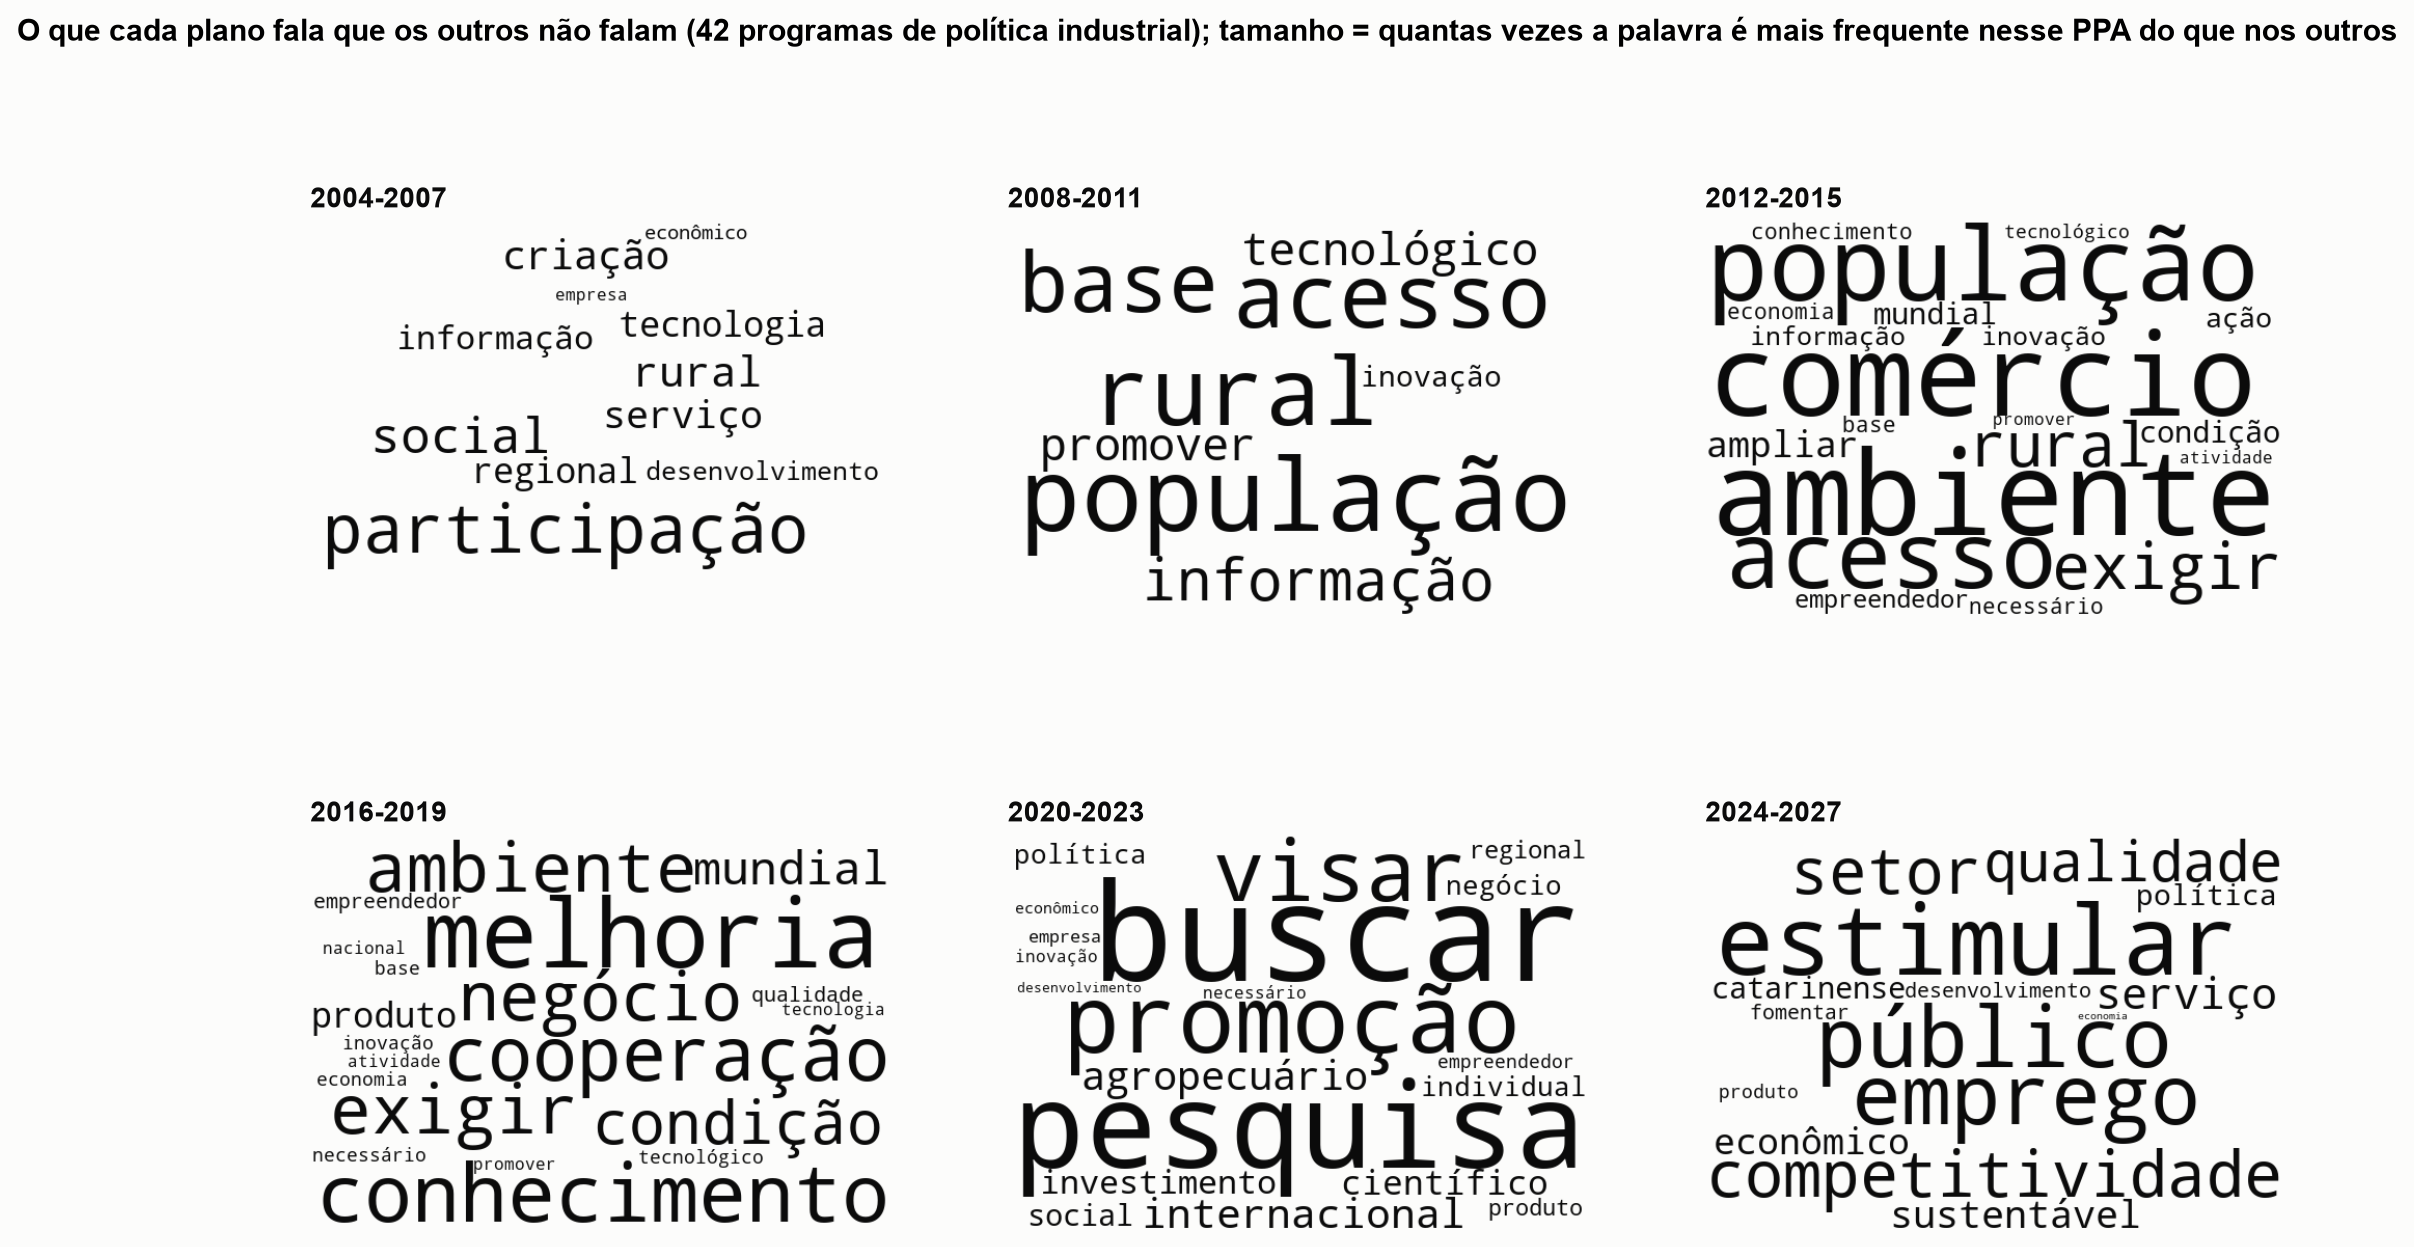

**Palavras características**

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,participação,população,ambiente,melhoria,buscar,estimular
2,social,rural,comércio,conhecimento,pesquisa,público
3,rural,acesso,população,cooperação,promoção,emprego
4,criação,base,acesso,ambiente,visar,competitividade
5,serviço,informação,exigir,exigir,internacional,setor
6,tecnologia,tecnológico,rural,negócio,agropecuário,qualidade
7,regional,promover,ampliar,condição,científico,serviço
8,informação,inovação,condição,mundial,investimento,sustentável
9,desenvolvimento,,mundial,produto,social,econômico


**Bigramas** (ocorrências entre parênteses)

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,desenvolvimento regional (2),base tecnológico (2),ampliar acesso (2),ampliar acesso (2),científico tecnológico (3),desenvolvimento econômico (4)
2,rural pesqueiro (2),população rural (2),condição necessário (2),científico tecnológico (2),ampliar acesso (2),aumento competitividade (2)
3,social econômico (2),rural pescador (2),economia mundial (2),condição necessário (2),condição necessário (2),competitividade economia (2)
4,,,fomentar atividade (2),economia mundial (2),pequeno empresa (2),emprego qualificar (2)
5,,,pequeno empresa (2),pequeno empresa (2),comercial cooperação (2),empresa catarinense (2)
6,,,acadêmico empresarial (2),economia catarinense (2),cooperação internacional (2),geração emprego (2)
7,,,ambiente acadêmico (2),empreendedor individual (2),cultural social (2),promover desenvolvimento (2)
8,,,comércio exterior (2),empresa empreendedor (2),desenvolvimento regional (2),economia catarinense (2)
9,,,economia catarinense (2),inovação tecnológico (2),economia catarinense (2),empreendedor individual (2)


**Trigramas** (ocorrências entre parênteses)

C:\Users\andre\AppData\Local\Temp\ipykernel_23588\2502610693.py:11: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(x.pivot(index="posição", columns="periodo", values="txt").reindex(columns=PER).fillna(""))


periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,,,ambiente acadêmico empresarial (2),empresa empreendedor individual (2),comercial cooperação internacional (2),
2,,,empresa empreendedor individual (2),,cooperação internacional área (2),
3,,,,,econômico política cultural (2),
4,,,,,empresa empreendedor individual (2),
5,,,,,internacional missão promoção (2),
6,,,,,internacional área econômico (2),
7,,,,,missão promoção comercial (2),
8,,,,,pesquisa científico tecnológico (2),
9,,,,,política cultural social (2),


In [4]:
pc = palavras_caracteristicas(p)
fig("historia_palavras_selecionados.png", 1000)
g = pc[(pc.recorte == "selecionados") & (pc.medida == "contagem")]
display(Markdown("**Palavras características**"))
display(g.pivot(index="posição", columns="periodo", values="palavra").reindex(columns=PER).fillna(""))
ng = item7_ngramas(f)
for n, nome in ((2, "Bigramas"), (3, "Trigramas")):
    g = ng[(ng.recorte == "texto, selecionados") & (ng.n == n)]
    x = g.assign(txt=g.ngrama + " (" + g["ocorrências"].astype(str) + ")")
    display(Markdown(f"**{nome}** (ocorrências entre parênteses)"))
    display(x.pivot(index="posição", columns="periodo", values="txt").reindex(columns=PER).fillna(""))

**Leitura:** a sequência é nítida: **participação, social e rural** (2004-2007); **população, acesso, rural, base tecnológica e informação** (2008-2011); **comércio, ambiente de inovação, conhecimento, empreendedor e negócio** (2012-2019); **pesquisa, promoção, internacional e científico** (2020-2023); **competitividade, emprego, setor, estimular e público** (2024-2027). Os bigramas contam a mesma história: desenvolvimento regional e rural pesqueiro (2004-2007); base tecnológica e população rural (2008-2011); economia mundial, comércio exterior, pequena empresa e inovação tecnológica (2012-2019); científico-tecnológico e cooperação internacional (2020-2023); e, em 2024-2027, **desenvolvimento econômico** (em 4 programas), **aumento da competitividade, competitividade da economia, empresa catarinense e geração de emprego**. Trigramas quase não se repetem, porque o texto de cada programa é curto: os poucos que aparecem são "ambiente acadêmico empresarial" e "empresa empreendedor individual" (2012-2019) e, em 2020-2023, os do 0212 sobre missões e promoção comercial. Contagens pequenas: 2 a 4 repetições.

## 2. Competitividade sobe, inovação cai

% dos lemas de cada tema por PPA, no plano inteiro e na política industrial. Teste principal: variação (limite corrigido ≈ 0,008); tendência complementar.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_temas.png


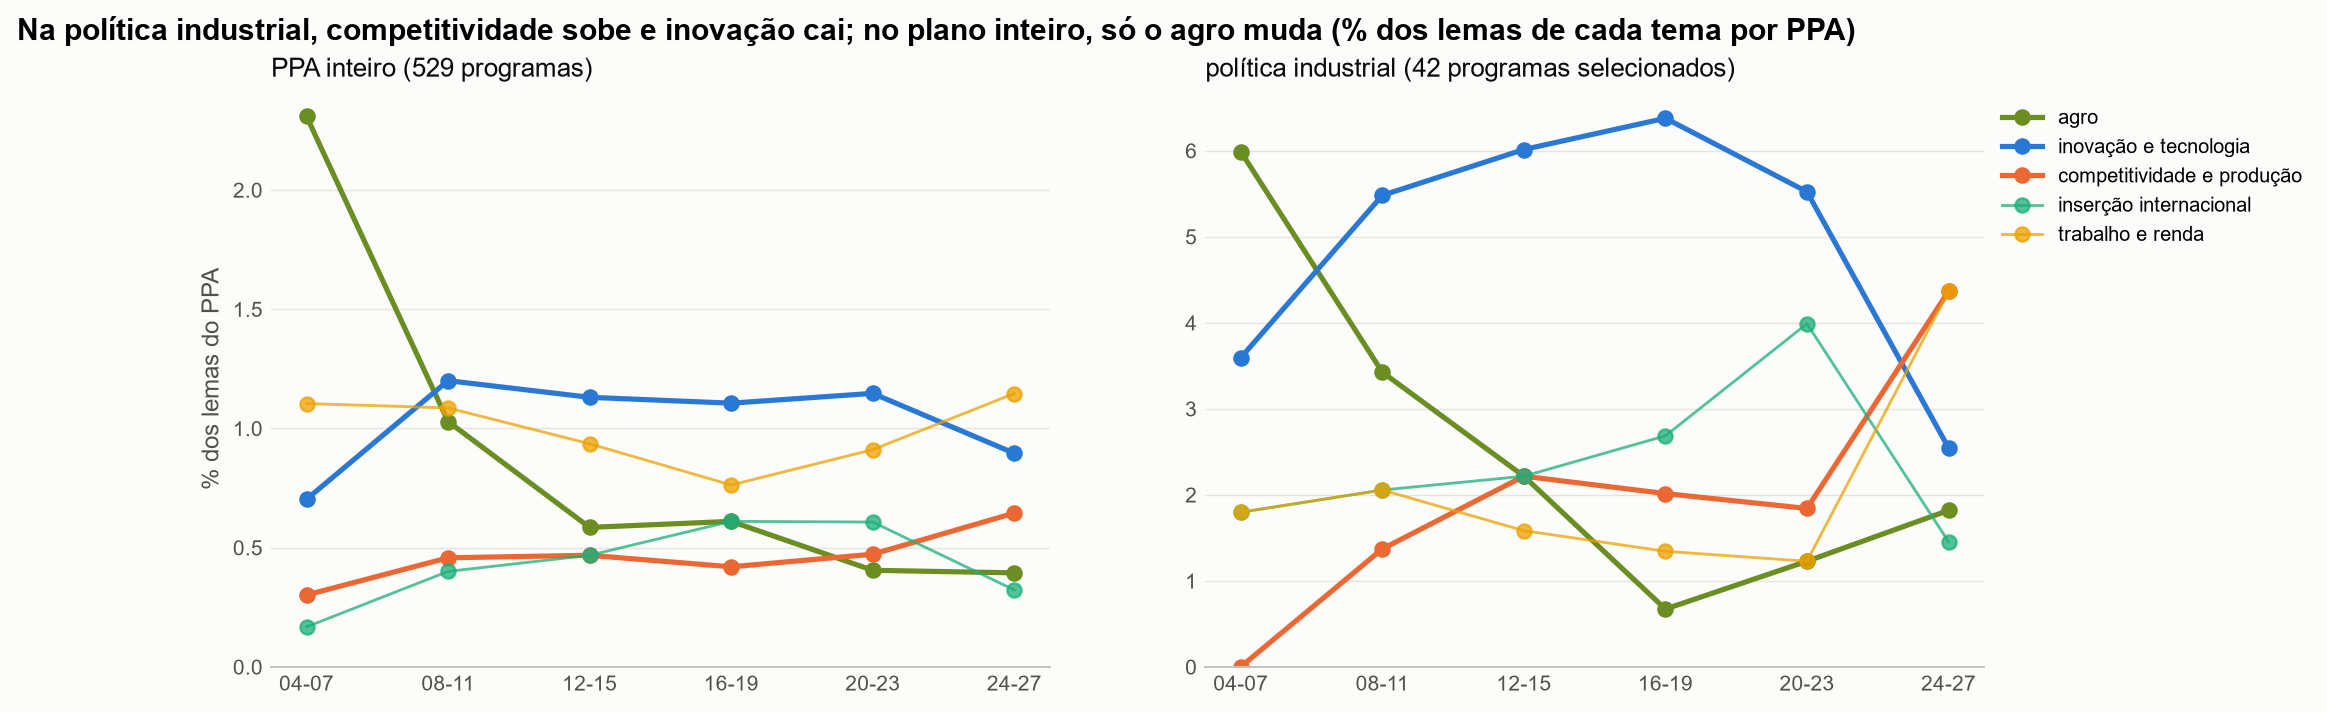

recorte,tema,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027,p variação,p tendência
PPA inteiro,agro,"2,31","1,03","0,58","0,61","0,40","0,39","0,004","0,015"
PPA inteiro,inovação e tecnologia,"0,70","1,20","1,13","1,11","1,15","0,90","0,922","1,000"
PPA inteiro,competitividade e produção,"0,30","0,46","0,47","0,42","0,47","0,64","0,677","0,053"
PPA inteiro,inserção internacional,"0,17","0,40","0,47","0,61","0,61","0,32","0,619","0,485"
PPA inteiro,trabalho e renda,"1,10","1,09","0,94","0,76","0,91","1,15","0,941","0,920"
selecionados,agro,"5,99","3,42","2,22","0,67","1,23","1,82","0,741","0,091"
selecionados,inovação e tecnologia,"3,59","5,48","6,01","6,38","5,52","2,55","0,932","1,000"
selecionados,competitividade e produção,"0,00","1,37","2,22","2,01","1,84","4,36","0,004","0,098"
selecionados,inserção internacional,"1,80","2,05","2,22","2,68","3,99","1,45","0,851","0,806"
selecionados,trabalho e renda,"1,80","2,05","1,58","1,34","1,23","4,36","0,821","0,927"


Ocorrências por PPA:

recorte,tema,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,agro,69,18,15,16,12,11
PPA inteiro,inovação e tecnologia,21,21,29,29,34,25
PPA inteiro,competitividade e produção,9,8,12,11,14,18
PPA inteiro,inserção internacional,5,7,12,16,18,9
PPA inteiro,trabalho e renda,33,19,24,20,27,32
selecionados,agro,10,5,7,2,4,5
selecionados,inovação e tecnologia,6,8,19,19,18,7
selecionados,competitividade e produção,0,2,7,6,6,12
selecionados,inserção internacional,3,3,7,8,13,4
selecionados,trabalho e renda,3,3,5,4,4,12


In [5]:
temas = temas_no_tempo(p)
fig("historia_temas.png", 1050)
tabela(temas[["recorte", "tema"] + PER + ["p variação", "p tendência"]], 2)
display(Markdown("Ocorrências por PPA:"))
tabela(temas[["recorte", "tema"] + [f"{q} n" for q in PER]].rename(columns=lambda c: c.replace(" n", "")), 0)

**Leitura:** na política industrial, **competitividade e produção**, que não existe em 2004-2007, fica perto de 2% dos lemas de 2012 a 2023 e sobe para **4,4% em 2024-2027**. É o único tema da política industrial que varia além do acaso (p = 0,004, abaixo do limite corrigido). **Inovação e tecnologia** sobem de 3,6% em 2004-2007 para 6,4% em 2016-2019 e caem para 2,5% em 2024-2027, mas essa queda, sozinha, **não passa no teste**. Trabalho e renda também sobe em 2024-2027 (4,4%, puxado pelo 0354), e inserção internacional tem seu pico em 2020-2023 (4,0%, pelo 0212). No plano inteiro as curvas são quase planas, com exceção do agro (capítulo 9). O que sobe no discurso, portanto, é **competitividade e emprego**, não o vocabulário de política industrial como um todo, que fica estável em torno de 12% dos lemas desde 2012. Contagens pequenas: de 0 a 19 ocorrências por tema e PPA.

## 3. A inovação sai da política industrial

De onde vem o vocabulário de inovação do plano (inovação, tecnologia, modernização, tecnológico): dos programas de política industrial ou dos demais?

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_quem_fala_inovacao.png


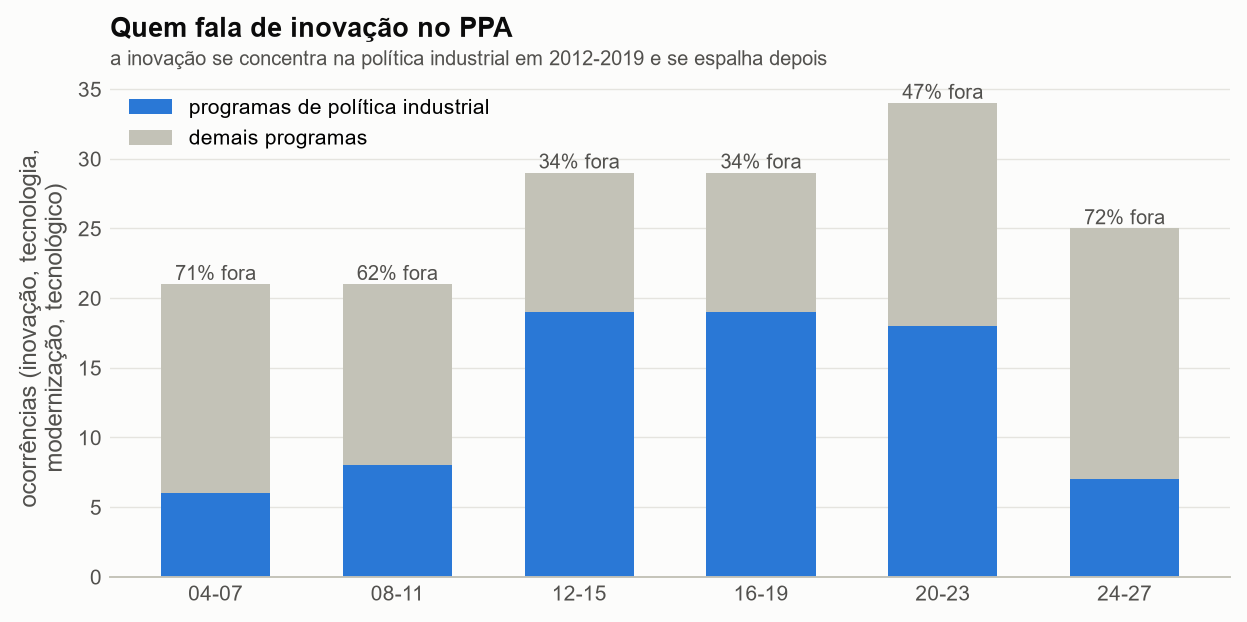

PPA,ocorrências nos selecionados,ocorrências nos demais programas,% fora da política industrial
2004-2007,6,15,"71,4"
2008-2011,8,13,"61,9"
2012-2015,19,10,"34,5"
2016-2019,19,10,"34,5"
2020-2023,18,16,"47,1"
2024-2027,7,18,"72,0"


PPA,programas de fora que mais usam o vocabulário de inovação
2004-2007,0226 Leite e Carne em Pastagem Melhorada (3); 0502 Gestão da Tecnologia da Informação e Comunica (2); 0600 Apoio Administrativo - Celesc (2); 0170 Modernização da Gestão de Materiais e Serviço (1)
2008-2011,0430 Descentralização da Média e Alta Complexidade (2); 0840 PNAGE - Programa Nacional de Apoio à Moderniz (2); 0905 Gestão Administrativa - Celesc (2); 0220 Governança Eletrônica (1)
2012-2015,0220 Governança Eletrônica (2); 0840 PNAGE - Programa Nacional de Apoio à Moderniz (2); 0830 Modernização da Administração Fazendária (1); 0145 Elaboração de Projetos e Estudos de Infraestr (1)
2016-2019,0220 Governança Eletrônica (2); 0830 Modernização da Administração Fazendária (1); 0145 Elaboração de Projetos e Estudos de Infraestr (1); 0250 Inclusão Digital (1)
2020-2023,0430 Atenção de Média e Alta Complexidade Ambulato (3); 0701 Redução da Criminalidade (2); 0704 Melhoria Estrutural da Segurança Pública (2); 0115 Gestão do Sistema de Transporte Intermunicipa (1)
2024-2027,0701 Redução da Criminalidade (2); 0704 Melhoria Estrutural da Segurança Pública (2); 0770 DETRAN Digital (2); 0430 Atenção Especializada à Saúde (2)


In [6]:
qf, quem = quem_fala_de_inovacao(p)
fig("historia_quem_fala_inovacao.png", 800)
tabela(qf, 1)
with pd.option_context("display.max_colwidth", None):
    display(quem.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

**Leitura:** em 2012-2019, dois terços do vocabulário de inovação do plano estavam na política industrial. Em 2024-2027, **72% estão fora dela**: segurança pública (0701 Redução da Criminalidade, 0704), DETRAN Digital, saúde. A inovação deixa de ser palavra da política produtiva e vira palavra de modernização do Estado. Em 2024-2027, "inovação" aparece na mesma frase que "público" e "serviço", e nas subações dos selecionados surge "inovação na gestão pública" já em 2020-2023.

## 4. Competitividade: com quem ela anda

Palavras que mais aparecem na mesma frase que competitividade e que inovação, nas duas metades do período. Proximidade: frases com as duas palavras divididas pelas frases da mais frequente delas (de 0 a 1). Entre parênteses: proximidade; nº de frases juntas; % de 200 reamostragens das frases em que a palavra continua entre as 6 mais próximas.

In [7]:
viz = pd.read_csv(S / "rede_termos_vizinhos_metades.csv")
viz = viz[viz.alvo.isin(["competitividade", "inovação"])]
with pd.option_context("display.max_colwidth", None):
    display(viz.rename(columns={viz.columns[-1]: "palavras mais próximas"})
            .style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

alvo,metade,frases,palavras mais próximas
inovação,2004-2015,9,"tecnológico (0.50; 7; 88%), base (0.36; 4; 49%), fomentar (0.33; 3; 38%), competitividade (0.25; 3; 19%), produtivo (0.22; 2; 16%), princípio (0.22; 2; 22%)"
competitividade,2004-2015,12,"bem (0.33; 4; 67%), produtivo (0.25; 3; 54%), inovação (0.25; 3; 46%), base (0.25; 3; 35%), tecnológico (0.21; 3; 36%), socioambiental (0.17; 2; 31%)"
inovação,2016-2027,18,"tecnologia (0.28; 5; 58%), incentivar (0.28; 5; 64%), empresa (0.26; 5; 49%), tecnológico (0.24; 8; 56%), setor (0.22; 4; 50%), regional (0.22; 4; 38%)"
competitividade,2016-2027,24,"empresa (0.29; 7; 72%), economia (0.26; 7; 56%), produtivo (0.25; 6; 63%), aumento (0.25; 6; 50%), econômico (0.24; 8; 50%), fomentar (0.23; 6; 47%)"


**Leitura:** em 2004-2015, competitividade aparece com **produtivo, inovação, base e tecnológico**; em 2016-2027, com **empresa, economia, aumento e econômico**, e inovação sai da vizinhança. A alta de competitividade está no texto novo: contando só as frases reescritas, ela vai de 1,8% para 5,3% dos lemas da política industrial em 2024-2027. Junto com o capítulo 3, é isso que sustenta a leitura de que a competitividade ocupa o lugar que a inovação tinha.

## 5. O que dizem x o que fazem

Quanto os programas de política industrial se parecem entre si, comparado com o resto do plano, em duas camadas: o texto (objetivo + justificativa, **o que dizem**) e os nomes das subações (**o que fazem**). A medida é a similaridade de vocabulário média entre os selecionados dividida pela similaridade média entre eles e os demais programas; acima de 1, o grupo é mais parecido entre si do que com o resto. Depois, os bigramas e trigramas dos nomes das subações dos selecionados (sem o produto e a unidade de medida que o PDF cola no nome).

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_dizem_fazem.png


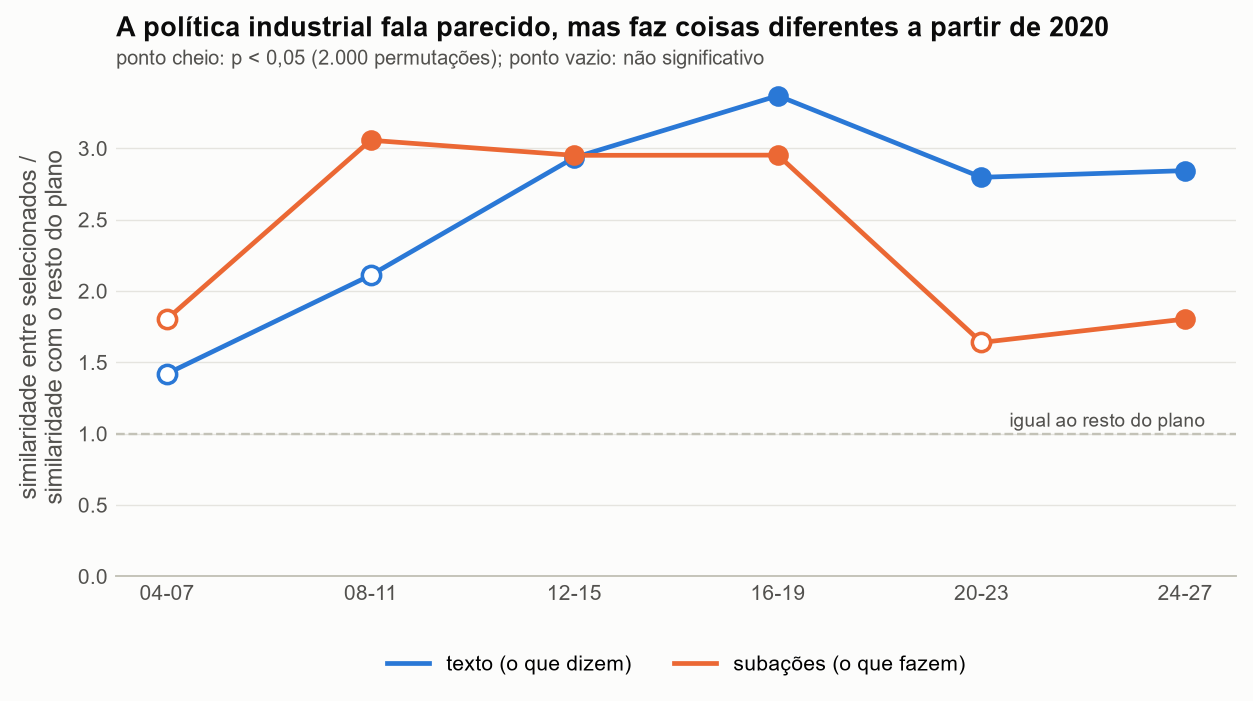

PPA,texto: razão,texto: p,subações: razão,subações: p
2004-2007,"1,42","0,094","1,80","0,064"
2008-2011,"2,11","0,065","3,06","0,018"
2012-2015,"2,93","0,005","2,95","0,002"
2016-2019,"3,37","0,006","2,95","0,002"
2020-2023,"2,80","0,003","1,64","0,084"
2024-2027,"2,84","0,002","1,80","0,030"


**Bigramas das subações** (ocorrências entre parênteses)

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,micro pequeno (4),estudo projeto (5),construção centro (3),financeiro projeto (4),fomentar desenvolvimento (3),fomentar projeto (2)
2,desenvolvimento produção (4),creditício empresa (3),ciência tecnologia (3),centro inovação (2),gestão público (3),informação comunicação (2)
3,implantação projeto (3),levantamentos estudo (3),agricultura orgânico (2),inovação tecnológico (2),inovação gestão (3),qualificação capacitação (2)
4,manutenção equipamento (3),desenvolvimento tecnológico (2),capacitação treinamento (2),projeto pesquisa (2),projeto pesquisa (2),tecnologia informação (2)
5,produto serviço (2),comércio exterior (2),centro inovação (2),projeto programa (2),projeto programa (2),fomentar desenvolvimento (2)
6,rural pesqueiro (2),cooperação internacional (2),desenvolvimento regional (2),capacitação treinamento (2),desenvolvimento produto (2),projeto desenvolvimento (2)
7,agregação produto (2),creditício desenvolvimento (2),econômico tecnológico (2),construção centro (2),evento relacionar (2),projeto incentivo (2)
8,capacitação gestor (2),cálculo publicação (2),fomento pesquisa (2),fomentar desenvolvimento (2),fomentar projeto (2),rural pesqueiro (2)
9,comércio exterior (2),equipamento tecnológico (2),inovação tecnológico (2),pequeno empresa (2),fomentar realização (2),unidade regional (2)


**Trigramas das subações** (ocorrências entre parênteses)

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,desenvolvimento fruticultura clima (2),levantamentos estudo projeto (3),centro inovação tecnológico (2),centro inovação tecnológico (2),inovação gestão público (3),tecnologia informação comunicação (2)
2,implantação projeto desenvolvimento (2),,ciência tecnologia inovação (2),,fomentar desenvolvimento produto (2),
3,micro pequeno empresa (2),,econômico tecnológico sustentabilidade (2),,fomentar realização evento (2),
4,,,tecnológico sustentabilidade ambiental (2),,incentivo programa projeto (2),
5,,,,,realização evento relacionar (2),


In [8]:
tab_df = dizem_fazem()
fig("historia_dizem_fazem.png", 850)
tabela(tab_df, 2)
for n, nome in ((2, "Bigramas"), (3, "Trigramas")):
    g = ng[(ng.recorte == "subações, selecionados") & (ng.n == n)]
    x = g.assign(txt=g.ngrama + " (" + g["ocorrências"].astype(str) + ")")
    display(Markdown(f"**{nome} das subações** (ocorrências entre parênteses)"))
    display(x.pivot(index="posição", columns="periodo", values="txt").reindex(columns=PER).fillna(""))

**Leitura:** **no texto, a política industrial é um bloco** de 2012-2015 em diante: os selecionados são 2,8 a 3,4 vezes mais parecidos entre si do que com o resto do plano (p de 0,002 a 0,006). **Nas subações, o bloco existe de 2008 a 2019** (razão de cerca de 3, p até 0,02) **e se desfaz em 2020-2027** (1,6 e 1,8; p de 0,08 e 0,03). Os programas continuam falando a mesma língua, mas passam a fazer coisas diferentes: crédito no BADESC, bolsas na CT&I, folha da EPAGRI no 0310, emendas no 0210. A correlação entre o que cada programa diz e o que faz é baixa em todo o período (0,15 a 0,22). As subações mostram o que muda no fazer: micro e pequena empresa e produção rural (2004-2007); estudos e projetos, crédito a empresas e comércio exterior (2008-2011); centros de inovação tecnológica e ciência e tecnologia (2012-2019); inovação na gestão pública (2020-2023); tecnologia da informação e comunicação e qualificação (2024-2027).

## 6. Quem recebe

% do valor do PPA (sem pessoal e emendas) por público declarado no campo PÚBLICO-ALVO. O valor de um programa com mais de um público é dividido em partes iguais. Setor público e sociedade em geral, que somam de 70% a 90% do plano, ficam fora do gráfico e aparecem na tabela.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_quem_recebe.png


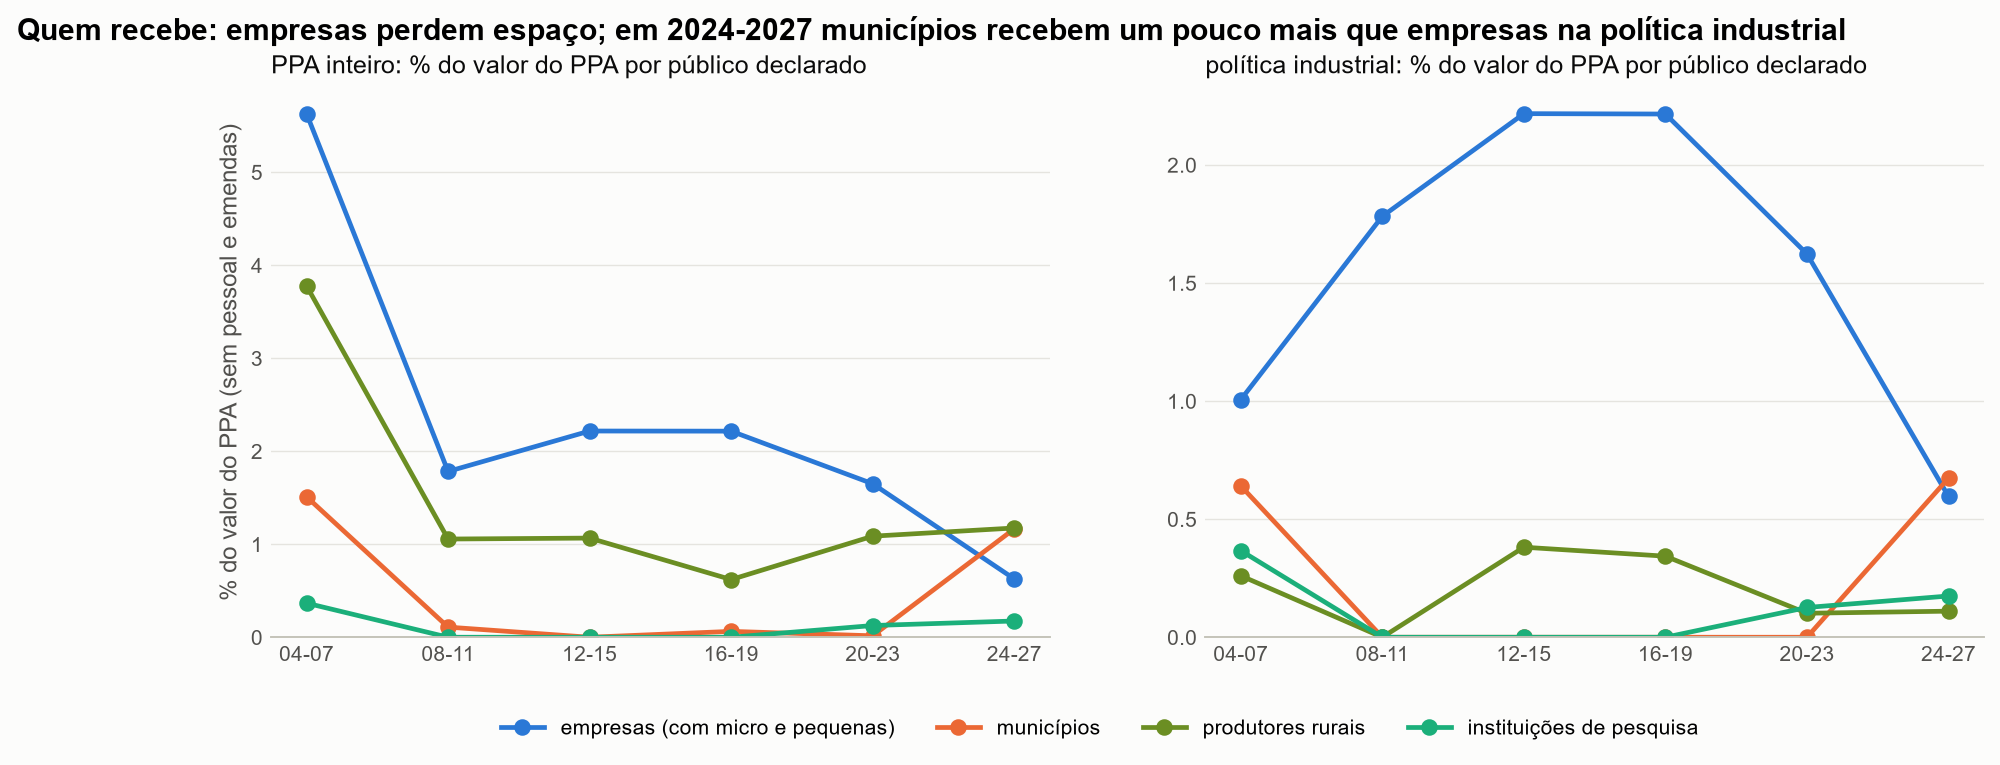

recorte,público,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,empresas (com micro e pequenas),"5,63","1,78","2,22","2,22","1,65","0,63"
PPA inteiro,estudantes e escolas,"6,43","0,80","9,76","3,97","7,85","10,80"
PPA inteiro,grupos vulneráveis,"1,08","1,55","3,40","2,44","3,22","2,00"
PPA inteiro,instituições de pesquisa,"0,37","0,00","0,00","0,00","0,13","0,17"
PPA inteiro,municípios,"1,51","0,11","0,00","0,06","0,02","1,17"
PPA inteiro,outros,"0,00","0,76","0,31","0,08","0,62","0,59"
PPA inteiro,produtores rurais,"3,78","1,06","1,07","0,62","1,09","1,17"
PPA inteiro,sem definição,"3,55","0,00","0,00","0,00","0,16","0,06"
PPA inteiro,setor público,"35,83","68,22","54,72","68,06","50,84","51,57"
PPA inteiro,sociedade em geral,"41,82","25,73","28,52","22,54","34,43","31,84"


In [9]:
tab_qr = quem_recebe()
fig("historia_quem_recebe.png", 1050)
tabela(tab_qr, 2)

**Leitura:** no plano inteiro, o público **empresas** (somando micro e pequenas) recebe 5,6% em 2004-2007 (puxado por programas fora da lista de política industrial: 0508 Gerar Investimentos, 0695 Gás Natural, 0710 Prodetur), 1,8% a 2,2% de 2008 a 2019 e **0,6% em 2024-2027**. Na política industrial, o valor dirigido a empresas cai de 2,2% do PPA (2012-2019) para 0,6% em 2024-2027, e **municípios passam a receber um pouco mais (0,67%)**, pelo 0200, cujo público declarado passa a ser "Municípios atendidos". "Trabalhadores" não aparece como público em nenhum programa de nenhum plano, nem no 0354 (Trabalho, Emprego e Renda). Ressalvas: público declarado, cortado em 50 caracteres no PDF; valores orçados.

## 7. A política industrial perde peso no orçamento

À esquerda, a fatia no orçamento do próprio PPA. À direita, o valor em reais por ano, a preços médios de 2024 (IPCA, IBGE/SIDRA tabela 1737). Os anexos de 2004-2007 e 2008-2011 trazem um ano só (2007 e 2011); os demais, o quadriênio, dividido por 4. Em 2024-2027 o deflator usa só 2024 e 2025, os anos com IPCA completo, e os valores são projeções do plano. Sem pessoal e emendas parlamentares.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_orcamento.png


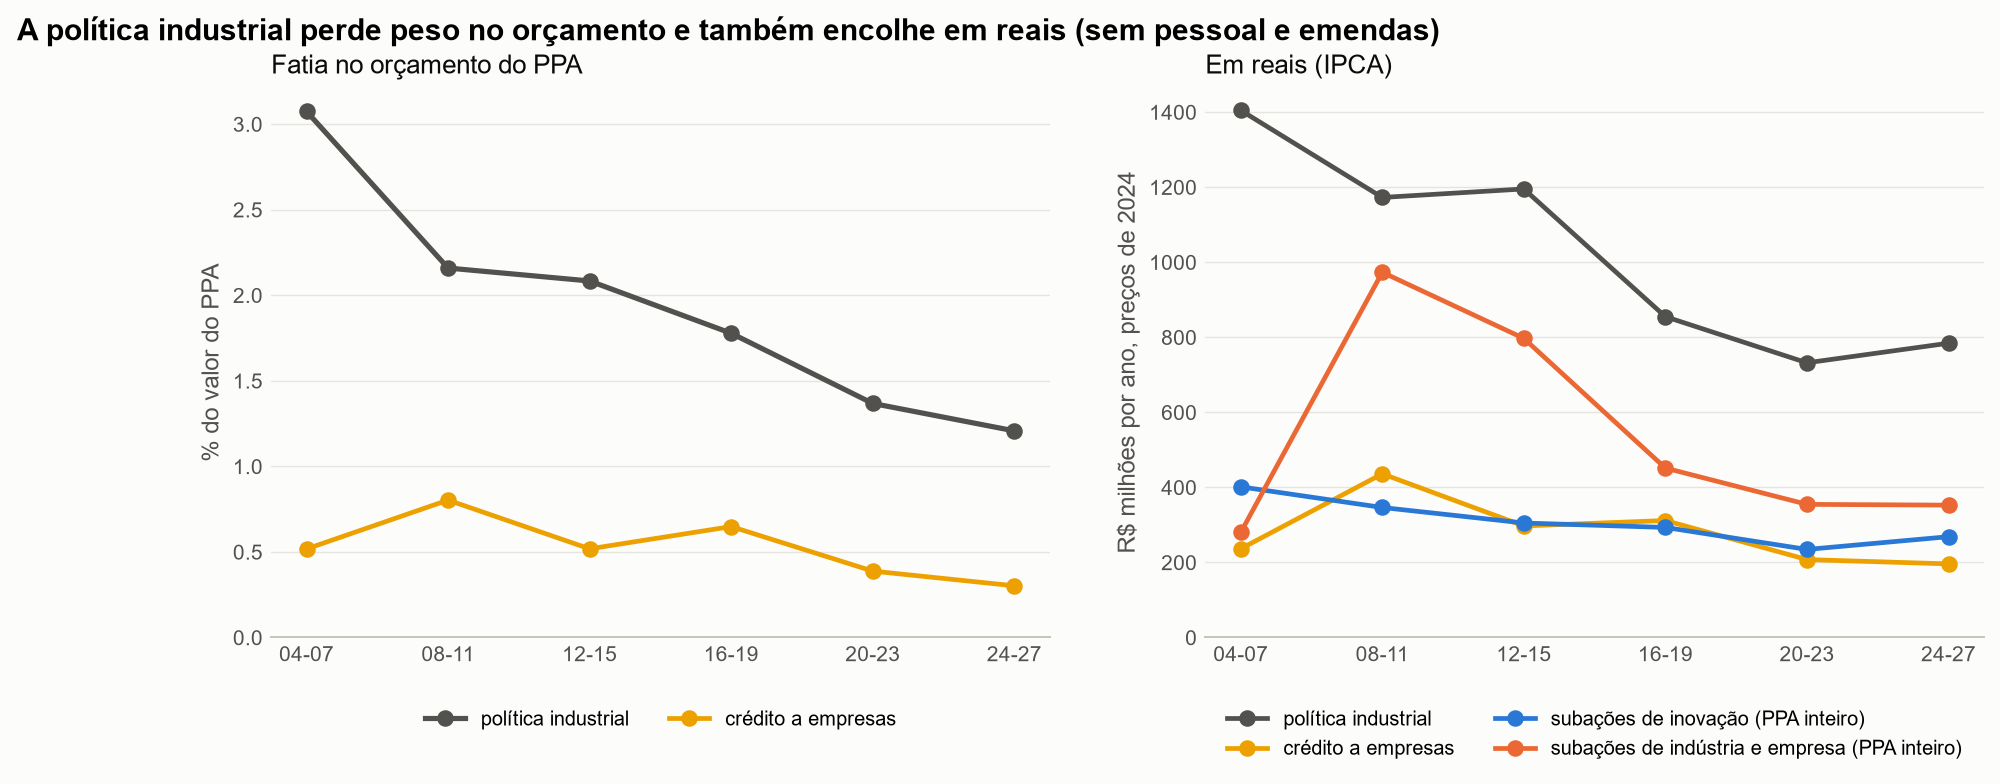

PPA,política industrial (% PPA),crédito a empresas (% PPA),"política industrial (R$ mi/ano, 2024)","crédito a empresas (R$ mi/ano, 2024)","subações de inovação (R$ mi/ano, 2024)","subações de indústria e empresa (R$ mi/ano, 2024)","PPA total (R$ bi/ano, 2024)"
2004-2007,"3,07","0,52","1.404,53","236,27","401,35","279,99","45,69"
2008-2011,"2,16","0,80","1.172,44","436,01","346,27","973,03","54,32"
2012-2015,"2,08","0,52","1.195,07","297,09","304,99","796,81","57,37"
2016-2019,"1,78","0,65","854,70","311,59","293,13","451,33","48,09"
2020-2023,"1,37","0,39","731,83","207,48","234,53","354,63","53,52"
2024-2027,"1,21","0,30","784,08","196,02","268,47","352,57","64,95"


In [10]:
tab_orc = orcamento(s)
fig("historia_orcamento.png", 1050)
tabela(tab_orc, 2)

**Leitura:** a fatia da política industrial **cai em todos os planos**, de 3,1% para 1,2% do PPA. Uma fatia pode cair só porque o resto do plano cresceu, mas não é o caso aqui: **em reais, a política industrial também encolhe**, de R$ 1,4 bilhão por ano (2007) para R$ 0,73 bilhão (2020-2023) e R$ 0,78 bilhão (2024-2027), enquanto o plano inteiro passa de R$ 46 bilhões para R$ 65 bilhões por ano. O crédito a empresas cai de R$ 436 milhões por ano (2011) para R$ 196 milhões; as subações de inovação do plano inteiro, de R$ 401 milhões (2007) para R$ 268 milhões. O discurso que sobe é o de competitividade e emprego (capítulo 2); o orçamento que deveria acompanhá-lo encolhe.

## 8. Planos copiados, política industrial reescrita

% dos lemas em frases iguais ou quase iguais (similaridade de 0,9 ou mais) às do PPA anterior. Tipo de transição (reeleição ou troca de governador): [verificar].

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_copia.png


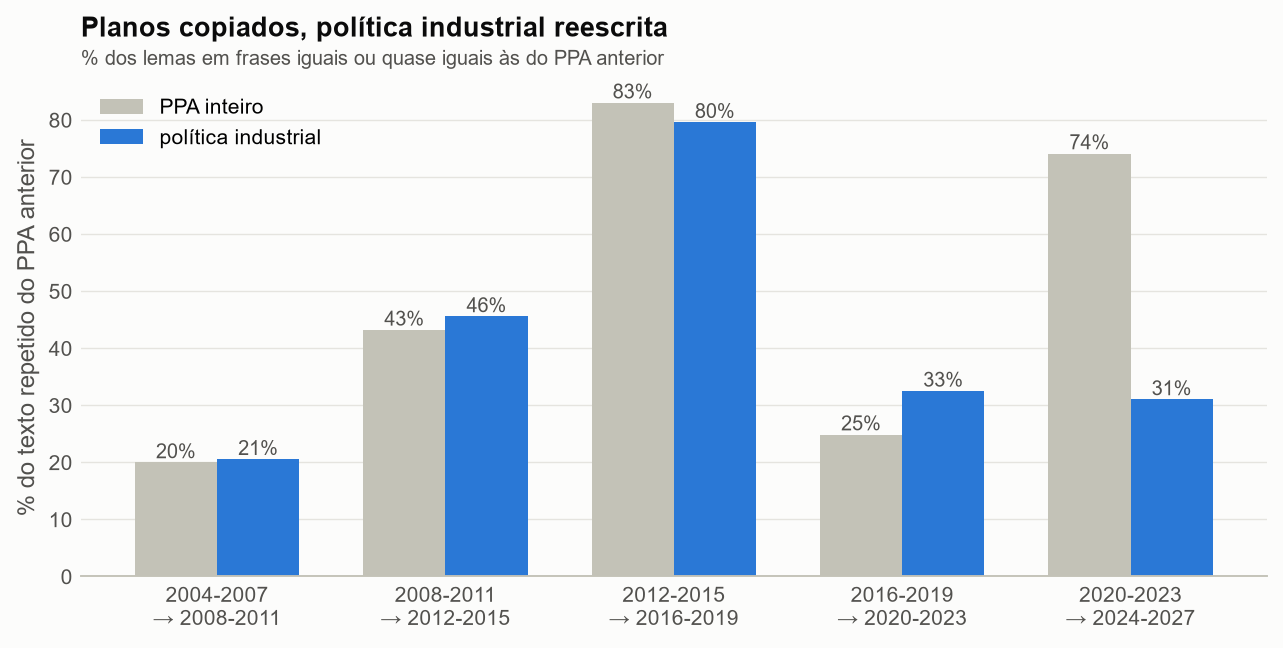

In [11]:
tab_copia = copia()
fig("historia_copia.png", 850)

**Leitura:** a reeleição de 2015 [verificar] copia 83% do texto. A troca de 2019 [verificar] copia só 25%, mas o formato do plano mudou em 2020-2023 (segundo os manuais do PPA, áreas de resultado e ações deram lugar a setores e subações [verificar nos manuais]), de modo que a baixa cópia pode ser efeito de formato, não de governo. Em 2023 também houve troca de governador [verificar], e o plano copiou **74%**. A ideia de que a troca de governo reescreve o plano **não se sustenta** com esses dados. O que se reescreve em 2024-2027 é a **política industrial** (31% de cópia), junto com a troca dos órgãos responsáveis: o 0342 e o novo 0353 passam para a Secretaria da Indústria, do Comércio e do Serviço, o 0230 para a de Ciência, Tecnologia e Inovação [verificar datas de criação], e o 0353 nasce de uma divisão do 0342 (77% do valor das subações vem dele).

## 9. Contraste: o agro sai do plano inteiro

Lateral ao tema do TCC, mas útil como contraste: é o único tema que muda de forma significativa no plano inteiro. Lista estrita aprovada em 19/11/2026: rural, agropecuário, agricultura, agrícola, agricultor, pesqueiro, pescador, pesca, aquicultor, aquicultura, produtor, leite, pecuária, agronegócio, florestal.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\historia_agro.png


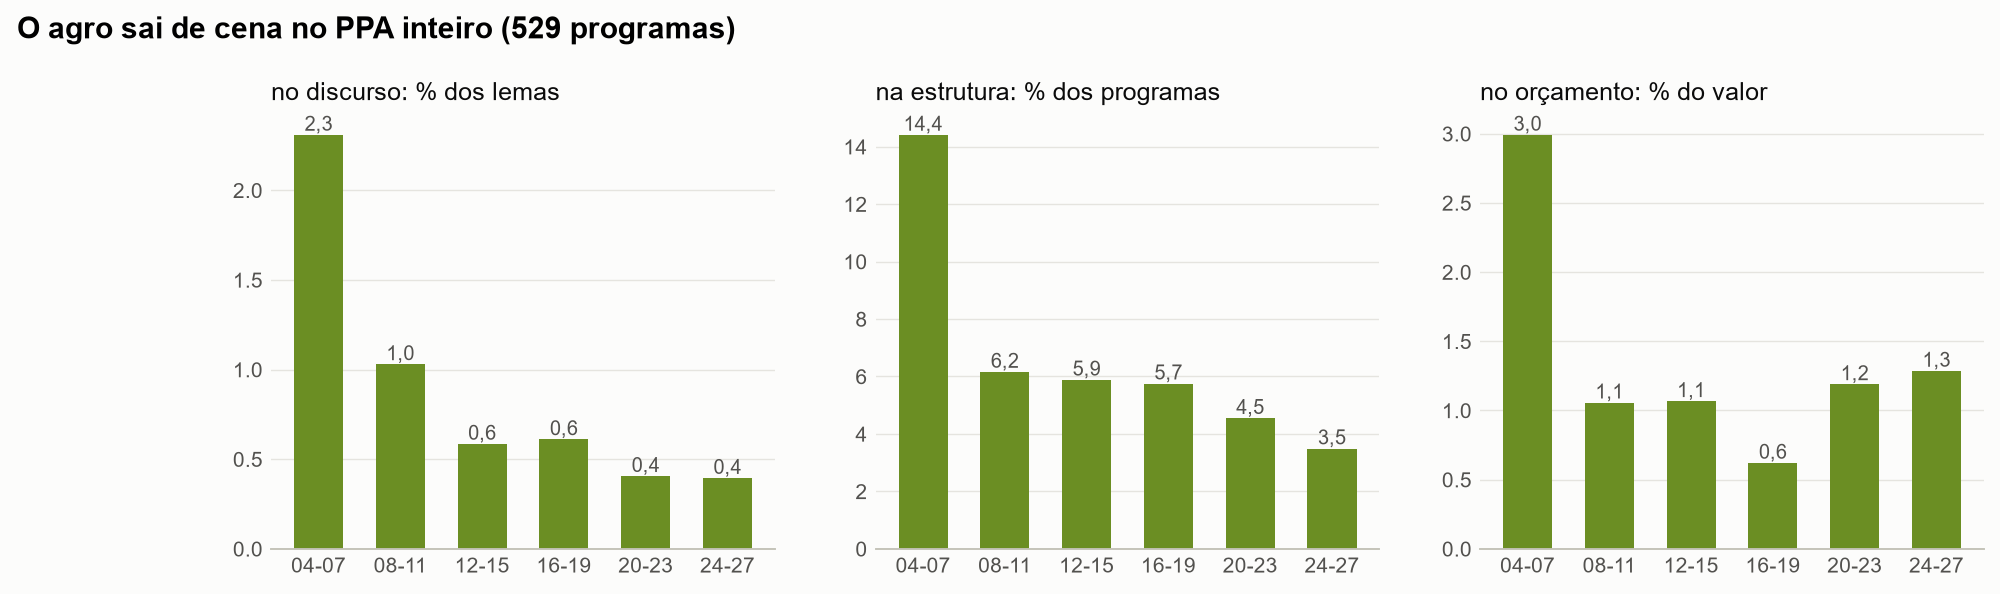

PPA,% dos lemas (tema agro),ocorrências de 'rural',% dos programas (área agricultura e pesca),programas da área,% do valor do PPA (sem pessoal e emendas)
2004-2007,"2,31",28,"14,41",17,"2,99"
2008-2011,"1,03",11,"6,15",4,"1,06"
2012-2015,"0,58",7,"5,88",5,"1,07"
2016-2019,"0,61",7,"5,75",5,"0,62"
2020-2023,"0,40",3,"4,55",4,"1,19"
2024-2027,"0,39",2,"3,49",3,"1,29"


In [12]:
tab_agro = agro(p, s, temas)
fig("historia_agro.png", 1000)
tabela(tab_agro, 2)

**Leitura:** o vocabulário agro cai de **2,3% dos lemas em 2004-2007 para 0,4% em 2024-2027** ("rural": de 28 ocorrências para 2). Pelo teste principal, a variação, a queda passa no limite corrigido (p = 0,004 < 0,008). A tendência (p = 0,015) é complementar e não passa no limite corrigido. A estrutura acompanha: a área de agricultura e pesca tinha 17 programas (14% do plano) em 2004-2007 e tem 3 (3,5%) em 2024-2027; parte disso é consolidação, porque o 2004-2007 tinha programas mais fragmentados. No orçamento, a fatia cai até 2016-2019 (de 3,0% para 0,6%) e se recupera em parte depois (1,3%).

## 10. Os planos se parecem?

Cosseno entre as contagens de lemas de cada PPA.

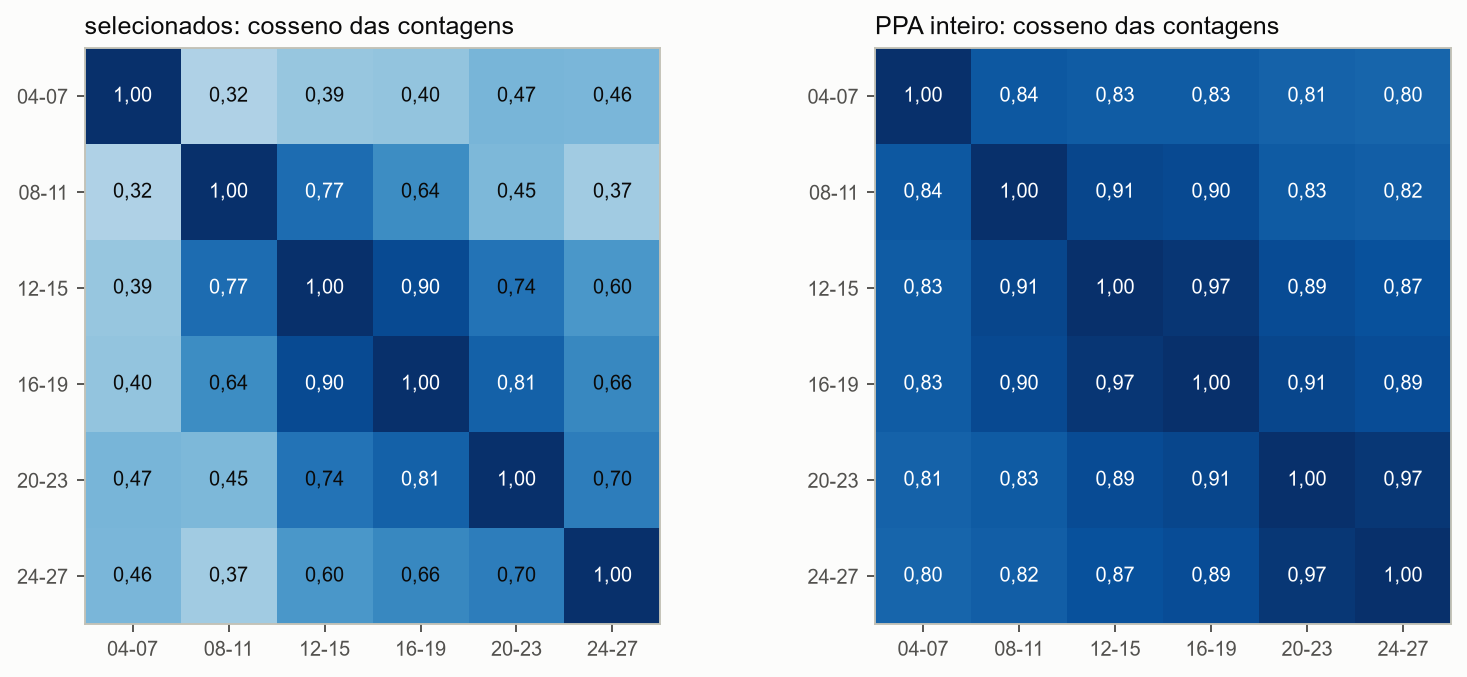

In [13]:
fig("contagem_similaridade_entre_ppas.png", 900)

**Leitura:** na política industrial, planos vizinhos são parecidos (0,70 a 0,90) e o 2004-2007 fica isolado (0,32 a 0,47). No plano inteiro todos se parecem (0,80 a 0,97), e 2020-2023 e 2024-2027 são quase iguais (0,97), coerente com a cópia de 74%.

## O que essa história permite dizer, e o que não permite

**Permite:** descrever a mudança do discurso da política industrial (da inovação à competitividade e ao emprego), mostrar que a inovação migra para a modernização do Estado, que a política industrial fala de forma coesa mas faz coisas cada vez mais diferentes, que o público empresa perde espaço e que o orçamento da política industrial encolhe em fatia e em reais.

**Não permite:** dizer que a política foi executada (o PPA é intenção e orçamento planejado), afirmar que uma palavra substituiu a outra com base num teste (só a alta de competitividade passa), atribuir as mudanças a governos sem conferir datas e fatos ([verificar]), nem tratar as contagens da política industrial como grandes (dezenas de ocorrências por PPA, no máximo).

**Para fechar a narrativa:** ligar cada capítulo ao contexto (política industrial federal de cada período, ciclo de commodities, criação das secretarias estaduais), todo marcado [verificar] em `docs/contexto-historico.md`, e conferir a contagem de programas contra a lista oficial.

## Apêndice A. Palavras características do plano inteiro

Mesma medida do capítulo 1, nos 529 programas (mínimo de 5 ocorrências). As palavras são quase todas de formato (gerências regionais em 2004-2007, portarias e blocos de financiamento da saúde em 2012-2019, "missão" e "institucional" em 2020-2023) e não contam história; o conteúdo só aparece em 2004-2007, com produtor, agricultor e pesqueiro.

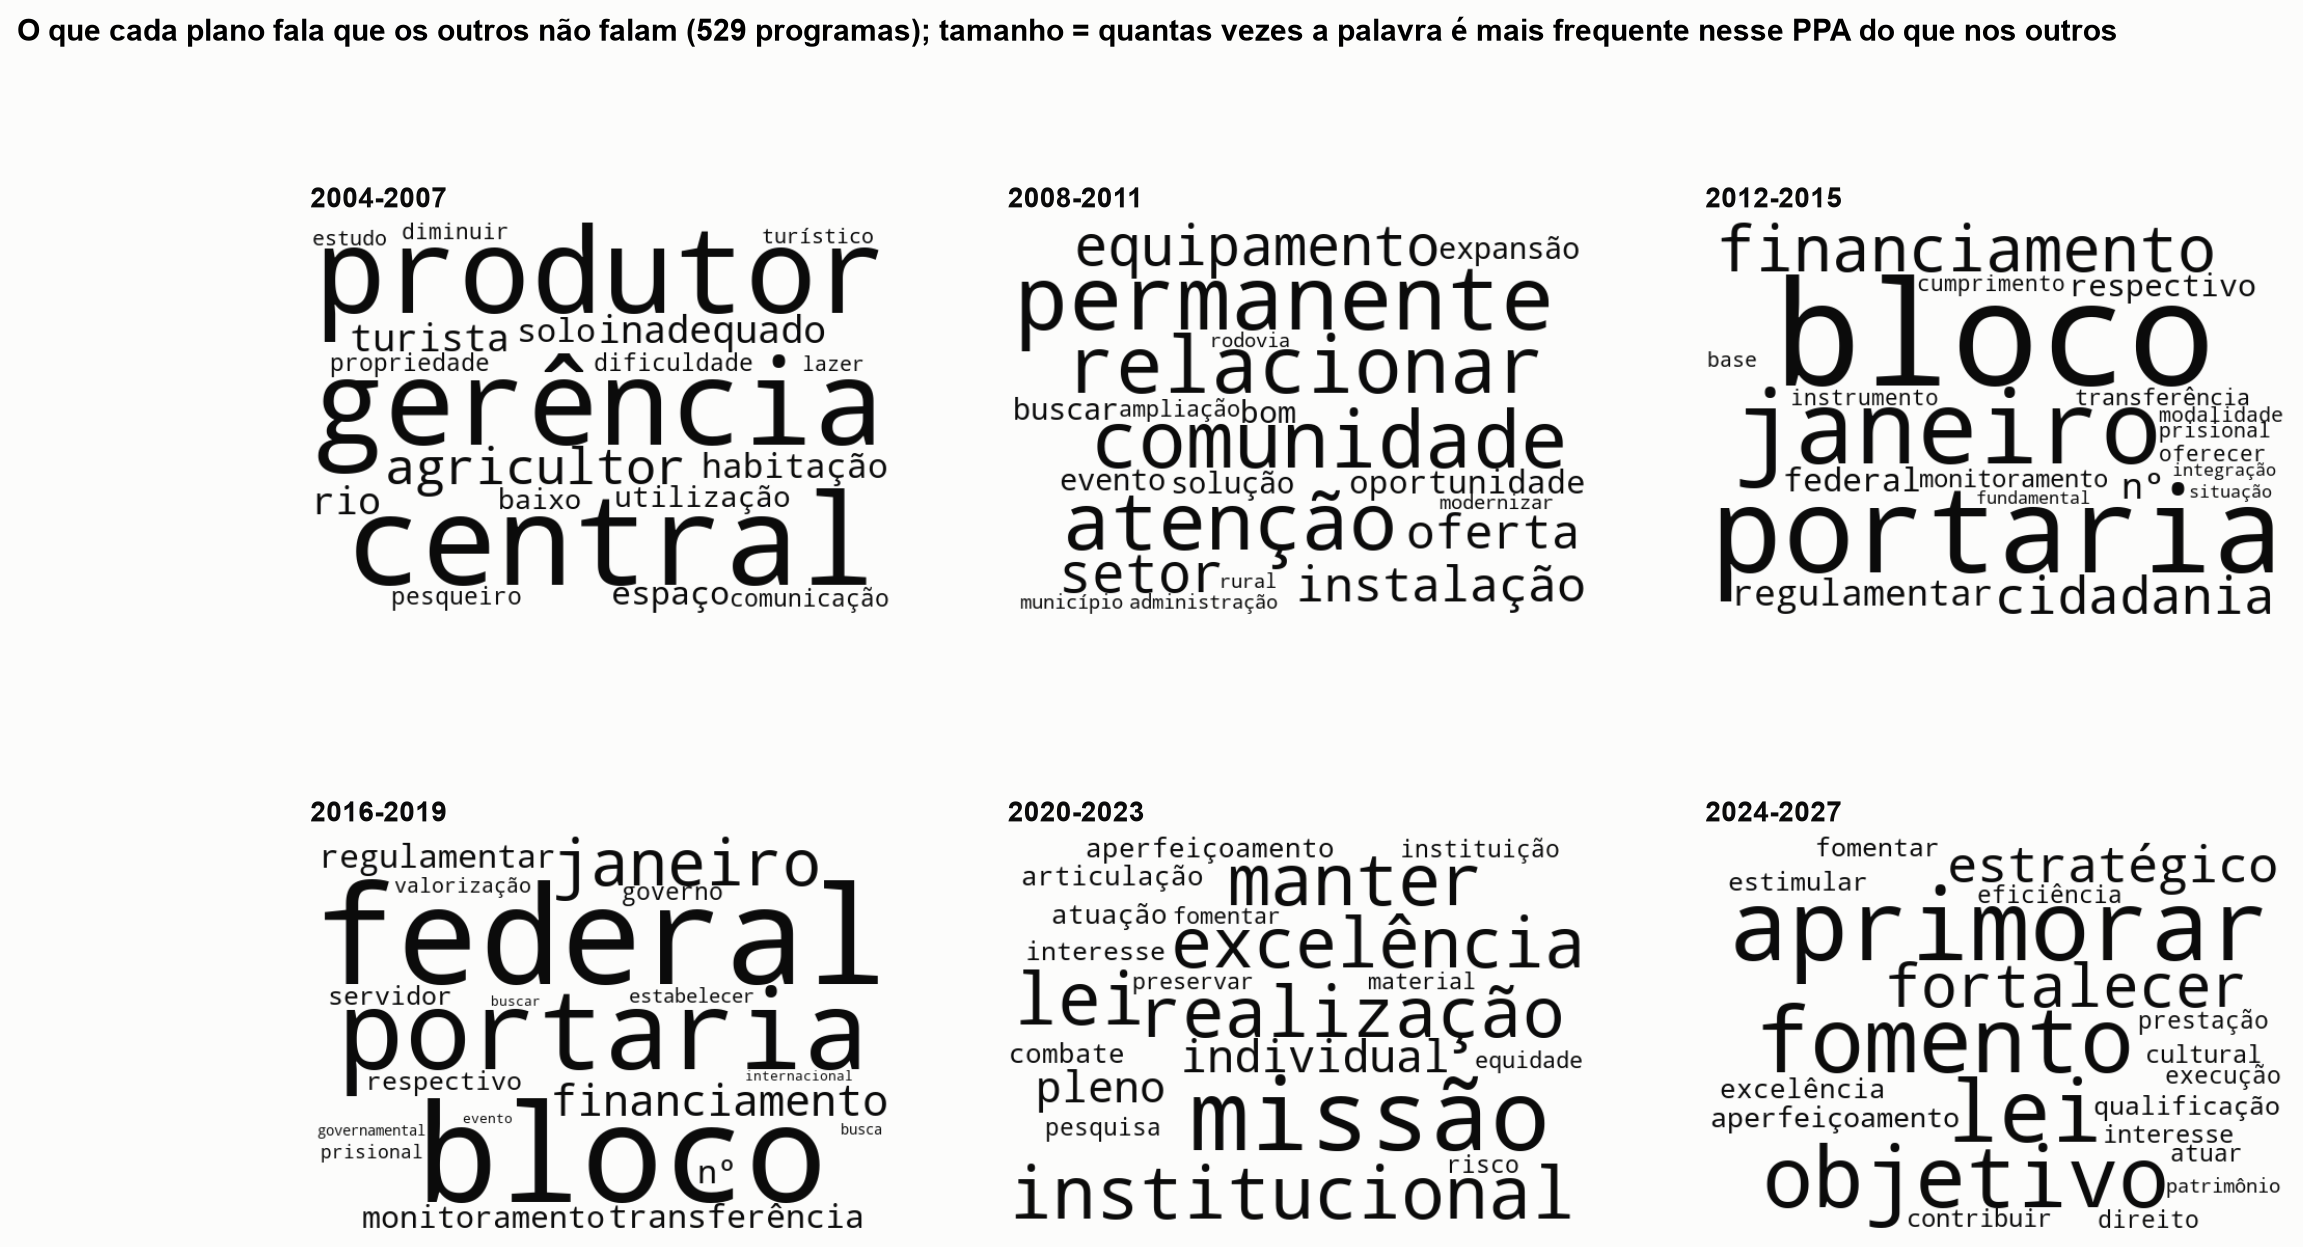

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,central,permanente,bloco,federal,missão,aprimorar
2,gerência,atenção,portaria,bloco,institucional,fomento
3,produtor,comunidade,janeiro,portaria,lei,lei
4,agricultor,relacionar,financiamento,janeiro,manter,objetivo
5,inadequado,equipamento,cidadania,financiamento,realização,fortalecer
6,rio,setor,regulamentar,transferência,excelência,estratégico
7,turista,instalação,nº,regulamentar,individual,aperfeiçoamento
8,habitação,oferta,federal,nº,pleno,excelência
9,espaço,oportunidade,respectivo,monitoramento,aperfeiçoamento,fomentar


In [14]:
fig("historia_palavras_ppa_inteiro.png", 1000)
g = pc[(pc.recorte == "PPA inteiro") & (pc.medida == "contagem")]
display(g.pivot(index="posição", columns="periodo", values="palavra").reindex(columns=PER).fillna(""))

## Apêndice B. TF-IDF de 20 palavras (versão anterior, só para comparação)

A primeira versão usava TF-IDF por PPA (documento = PPA, vocabulário de 200 palavras). A medida da história passou a ser a contagem; o TF-IDF fica aqui para mostrar a correspondência. Nos selecionados, ele reproduz a sequência do capítulo 1; no plano inteiro, devolve só palavras que todos os planos usam (necessidade, serviço, público).

In [15]:
for recorte in ("selecionados", "PPA inteiro"):
    g = pc[(pc.recorte == recorte) & (pc.medida == "TF-IDF")]
    display(Markdown(f"**{recorte}, TF-IDF**"))
    display(g.pivot(index="posição", columns="periodo", values="palavra").reindex(columns=PER).fillna(""))

**selecionados, TF-IDF**

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,participação,acesso,inovação,inovação,inovação,competitividade
2,social,população,tecnológico,catarinense,internacional,catarinense
3,rural,rural,acesso,tecnológico,catarinense,econômico
4,disponibilizar,tecnológico,economia,economia,empresa,desenvolvimento
5,tecnologia,propiciar,catarinense,promover,desenvolvimento,público
6,desenvolvimento,digital,promover,conhecimento,econômico,estimular
7,estimular,base,ambiente,empresa,tecnológico,qualidade
8,criação,inovação,população,condição,promover,definir
9,informação,informação,empresa,produto,pesquisa,qualificação


**PPA inteiro, TF-IDF**

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,necessidade,necessidade,necessidade,ação,público,público
2,serviço,catarinense,catarinense,promover,ação,promover
3,catarinense,desenvolvimento,qualidade,qualidade,serviço,serviço
4,ação,recurso,ação,necessidade,promover,ação
5,público,público,serviço,público,qualidade,social
6,rural,serviço,promover,recurso,catarinense,catarinense
7,recurso,condição,recurso,catarinense,gestão,desenvolvimento
8,gestão,gestão,desenvolvimento,desenvolvimento,recurso,qualidade
9,qualidade,qualidade,condição,serviço,necessidade,gestão
